In [1]:
from rdkit import Chem #RDKit Chemistry
from rdkit.Chem.Draw import IPythonConsole #RDKit drawing
from rdkit.Chem import Draw #RDKit drawing
# A few settings to improve the quality of structures 
from rdkit.Chem import rdDepictor
from rdkit.Chem import PandasTools #Add the ability to add a molecule to a dataframe
import mols2grid #The mols2grid library provides a convenient way of displaying molecules in a grid
import requests

IPythonConsole.ipython_useSVG = True
rdDepictor.SetPreferCoordGen(True)

In [2]:
mol = Chem.MolFromSmiles("c1ccccc1")

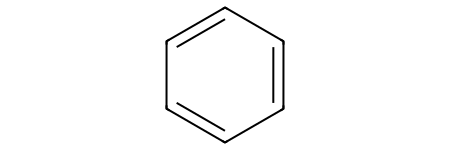

In [3]:
mol

In [4]:
glvc = Chem.MolFromSmiles("Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C")

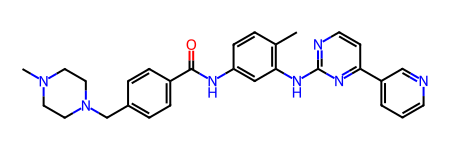

In [5]:
glvc

In [6]:
caffin=Chem.MolFromSmiles("CN1C(=O)N(C)c2ncn(C)c2C1=O")

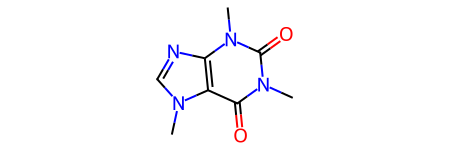

In [7]:
caffin

In [8]:
url = "https://raw.githubusercontent.com/PatWalters/practical_cheminformatics_tutorials/main/data/example_compounds.sdf"
r = requests.get(url)
bytes_written = open('example_compounds.sdf', 'w').write(r.text)

In [9]:
mols = [x for x in Chem.SDMolSupplier("example_compounds.sdf")]

In [10]:
mols

In [11]:
mols2grid.display(mols)

In [12]:
df = PandasTools.LoadSDF("example_compounds.sdf")

In [13]:
mols2grid.display(df,mol_col="ROMol")

In [14]:
from rdkit.Chem.Descriptors import MolWt
from rdkit.Chem.Crippen import MolLogP
df['MW'] = [MolWt(x) for x in df.ROMol]
df['LogP'] = [MolLogP(x) for x in df.ROMol]

In [15]:
def two_decimals(x):
    return f'{x:.2f}'
mols2grid.display(df,mol_col="ROMol",subset=["img","MW","LogP"],transform={"MW" : two_decimals, "LogP": two_decimals})

In [16]:
import seaborn as sns


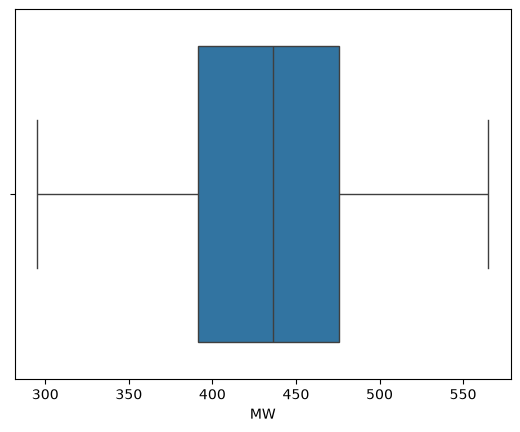

In [17]:
ax = sns.boxplot(x=df.MW)

In [18]:
df["ROMol"].head()

0    <rdkit.Chem.rdchem.Mol object at 0x146c9bed0>
1    <rdkit.Chem.rdchem.Mol object at 0x146c9ba00>
2    <rdkit.Chem.rdchem.Mol object at 0x146c9b990>
3    <rdkit.Chem.rdchem.Mol object at 0x146c9b920>
4    <rdkit.Chem.rdchem.Mol object at 0x146c9b8b0>
Name: ROMol, dtype: object

In [19]:
type(df["ROMol"].iloc[0])

rdkit.Chem.rdchem.Mol

In [21]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors
import mols2grid

smiles = [
    "CC(=O)OC1=CC=CC=C1C(=O)O",   # aspirin
    "CC(=O)NC1=CC=C(C=C1)O",       # paracetamol
    "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O" # ibuprofen
]

df = pd.DataFrame({"SMILES": smiles})

df["ROMol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df["MW"] = df["ROMol"].apply(Descriptors.MolWt)
df["LogP"] = df["ROMol"].apply(Descriptors.MolLogP)

def two_decimals(x):
    return f"{x:.2f}"

mols2grid.display(
    df,
    mol_col="ROMol",
    subset=["MW", "LogP"],
    transform={
        "MW": two_decimals,
        "LogP": two_decimals
    }
)

In [28]:
df.head()


,SMILES,ROMol,MW,LogP
0,CC(=O)OC1=CC=CC=C1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x147a08580>,180.159,1.3101
1,CC(=O)NC1=CC=C(C=C1)O,<rdkit.Chem.rdchem.Mol object at 0x147a08c10>,151.165,1.3506
2,CC(C)CC1=CC=C(C=C1)C(C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x147a08d60>,206.285,3.0732


In [29]:
df.dtypes

SMILES        str
ROMol      object
MW        float64
LogP      float64
dtype: object

In [25]:
type(df["ROMol"].iloc[0])


rdkit.Chem.rdchem.Mol

In [26]:
print(mols2grid.__version__)

2.2.0


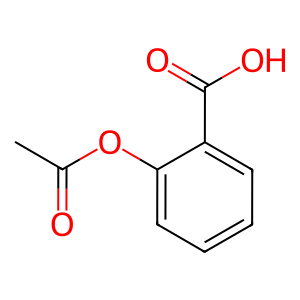

In [30]:
from rdkit import Chem
from rdkit.Chem import Draw

mol = Chem.MolFromSmiles("CC(=O)OC1=CC=CC=C1C(=O)O")
Draw.MolToImage(mol)

In [32]:
import pandas as pd

df_test = pd.DataFrame({
    "SMILES": [
        "CCO",
        "CC(=O)OC1=CC=CC=C1C(=O)O",
        "CC(=O)NC1=CC=C(O)C=C1"
    ]
})

mols2grid.display(df_test, smiles_col="SMILES")